In [1]:
# Healthcare Operations & Patient Analytics
# Step 1: import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
main_color = "#1f77b4"

In [2]:
# Step 2: load the two raw datasets
# Dataset 1: hospital admissions (patients, doctors, diagnosis, billing, test results)
admissions_data = pd.read_csv("Raw_Data/healthcare_dataset.csv")
# Dataset 2: outpatient appointments (scheduling, waiting time, no-shows)
appointments_data = pd.read_csv("Raw_Data/KaggleV2-May-2016.csv")

print("Admissions rows and columns:", admissions_data.shape)
print("Appointments rows and columns:", appointments_data.shape)

Admissions rows and columns: (55500, 15)
Appointments rows and columns: (110527, 14)


In [3]:
# Step 3: look at the admissions data
print(admissions_data.head())
print()
print(admissions_data.dtypes)

            Name  Age  Gender Blood Type Medical Condition Date of Admission  \
0  Bobby JacksOn   30    Male         B-            Cancer        2024-01-31   
1   LesLie TErRy   62    Male         A+           Obesity        2019-08-20   
2    DaNnY sMitH   76  Female         A-           Obesity        2022-09-22   
3   andrEw waTtS   28  Female         O+          Diabetes        2020-11-18   
4  adrIENNE bEll   43  Female        AB+            Cancer        2022-09-19   

             Doctor                    Hospital Insurance Provider  \
0     Matthew Smith             Sons and Miller         Blue Cross   
1   Samantha Davies                     Kim Inc           Medicare   
2  Tiffany Mitchell                    Cook PLC              Aetna   
3       Kevin Wells  Hernandez Rogers and Vang,           Medicare   
4    Kathleen Hanna                 White-White              Aetna   

   Billing Amount  Room Number Admission Type Discharge Date   Medication  \
0    18856.281306    

In [4]:
# Step 4: quality checks on the admissions data
print("Missing values:", admissions_data.isnull().sum().sum())
print("Duplicate rows:", admissions_data.duplicated().sum())
print("Negative billing amounts:", (admissions_data["Billing Amount"] < 0).sum())
print()
print(admissions_data["Billing Amount"].describe())

Missing values: 0
Duplicate rows: 534
Negative billing amounts: 108

count    55500.000000
mean     25539.316097
std      14211.454431
min      -2008.492140
25%      13241.224652
50%      25538.069376
75%      37820.508436
max      52764.276736
Name: Billing Amount, dtype: float64


In [5]:
# Step 5: clean the admissions data
admissions_clean = admissions_data.copy()
rows_before = len(admissions_clean)

# remove exact duplicate rows
admissions_clean = admissions_clean.drop_duplicates()
duplicates_removed = rows_before - len(admissions_clean)
print("Duplicates removed:", duplicates_removed)

# names have random upper and lower case letters, so make them consistent
admissions_clean["Name"] = admissions_clean["Name"].str.title()
admissions_clean["Doctor"] = admissions_clean["Doctor"].str.title()
admissions_clean["Hospital"] = admissions_clean["Hospital"].str.strip()

# negative billing amounts are invalid, so remove them
rows_before_billing = len(admissions_clean)
admissions_clean = admissions_clean[admissions_clean["Billing Amount"] > 0]
negative_billing_removed = rows_before_billing - len(admissions_clean)
print("Negative billing rows removed:", negative_billing_removed)

# convert date columns to real dates
admissions_clean["Date of Admission"] = pd.to_datetime(admissions_clean["Date of Admission"])
admissions_clean["Discharge Date"] = pd.to_datetime(admissions_clean["Discharge Date"])

# round billing to 2 decimals
admissions_clean["Billing Amount"] = admissions_clean["Billing Amount"].round(2)
print("Rows after cleaning:", len(admissions_clean))

Duplicates removed: 534
Negative billing rows removed: 106
Rows after cleaning: 54860


In [6]:
# Step 6: create new columns for the admissions data
# length of stay in days
admissions_clean["Length of Stay"] = (admissions_clean["Discharge Date"] - admissions_clean["Date of Admission"]).dt.days

# date parts for trend analysis
admissions_clean["Admission Year"] = admissions_clean["Date of Admission"].dt.year
admissions_clean["Admission Month"] = admissions_clean["Date of Admission"].dt.to_period("M").dt.to_timestamp()
admissions_clean["Admission Weekday"] = admissions_clean["Date of Admission"].dt.day_name()

# age groups
age_bins = [0, 18, 30, 45, 60, 75, 120]
age_labels = ["Under 18", "18-29", "30-44", "45-59", "60-74", "75+"]
admissions_clean["Age Group"] = pd.cut(admissions_clean["Age"], bins=age_bins, labels=age_labels, right=False)

# the dataset has no department column, so we map each medical condition to a department
department_map = {
    "Cancer": "Oncology",
    "Diabetes": "Endocrinology",
    "Hypertension": "Cardiology",
    "Obesity": "Nutrition & Bariatrics",
    "Asthma": "Pulmonology",
    "Arthritis": "Orthopedics",
}
admissions_clean["Department"] = admissions_clean["Medical Condition"].map(department_map)

# the first digit of the room number is the hospital floor
admissions_clean["Floor"] = "Floor " + (admissions_clean["Room Number"] // 100).astype(str)

# billing bands
billing_bins = [0, 10000, 20000, 30000, 40000, 100000]
billing_labels = ["Under 10k", "10k-20k", "20k-30k", "30k-40k", "40k+"]
admissions_clean["Billing Band"] = pd.cut(admissions_clean["Billing Amount"], bins=billing_bins, labels=billing_labels)

# test results are used as the patient outcome (Normal is a good outcome)
admissions_clean["Good Outcome"] = (admissions_clean["Test Results"] == "Normal").astype(int)
admissions_clean["Abnormal Result"] = (admissions_clean["Test Results"] == "Abnormal").astype(int)

# an admission id so each row can be counted as one admission
admissions_clean = admissions_clean.reset_index(drop=True)
admissions_clean["Admission ID"] = "ADM" + (admissions_clean.index + 1).astype(str).str.zfill(6)
print(admissions_clean[["Admission ID", "Department", "Floor", "Length of Stay", "Age Group", "Billing Band"]].head())

  Admission ID              Department    Floor  Length of Stay Age Group  \
0    ADM000001                Oncology  Floor 3               2     30-44   
1    ADM000002  Nutrition & Bariatrics  Floor 2               6     60-74   
2    ADM000003  Nutrition & Bariatrics  Floor 2              15       75+   
3    ADM000004           Endocrinology  Floor 4              30     18-29   
4    ADM000005                Oncology  Floor 4              20     30-44   

  Billing Band  
0      10k-20k  
1      30k-40k  
2      20k-30k  
3      30k-40k  
4      10k-20k  


In [7]:
# Step 7: look at the appointments data
print(appointments_data.head())
print()
print(appointments_data.dtypes)
print()
print("Missing values:", appointments_data.isnull().sum().sum())
print("Duplicate rows:", appointments_data.duplicated().sum())
print("Negative ages:", (appointments_data["Age"] < 0).sum())
print("Ages above 100:", (appointments_data["Age"] > 100).sum())

      PatientId  AppointmentID Gender          ScheduledDay  \
0  2.987250e+13        5642903      F  2016-04-29T18:38:08Z   
1  5.589978e+14        5642503      M  2016-04-29T16:08:27Z   
2  4.262962e+12        5642549      F  2016-04-29T16:19:04Z   
3  8.679512e+11        5642828      F  2016-04-29T17:29:31Z   
4  8.841186e+12        5642494      F  2016-04-29T16:07:23Z   

         AppointmentDay  Age      Neighbourhood  Scholarship  Hipertension  \
0  2016-04-29T00:00:00Z   62    JARDIM DA PENHA            0             1   
1  2016-04-29T00:00:00Z   56    JARDIM DA PENHA            0             0   
2  2016-04-29T00:00:00Z   62      MATA DA PRAIA            0             0   
3  2016-04-29T00:00:00Z    8  PONTAL DE CAMBURI            0             0   
4  2016-04-29T00:00:00Z   56    JARDIM DA PENHA            0             1   

   Diabetes  Alcoholism  Handcap  SMS_received No-show  
0         0           0        0             0      No  
1         0           0        0      

In [8]:
# Step 8: clean the appointments data
appointments_clean = appointments_data.copy()
rows_before = len(appointments_clean)

# fix the misspelled column names
appointments_clean = appointments_clean.rename(columns={
    "Hipertension": "Hypertension",
    "Handcap": "Handicap",
    "No-show": "No Show",
    "PatientId": "Patient ID",
    "AppointmentID": "Appointment ID",
    "ScheduledDay": "Scheduled Day",
    "AppointmentDay": "Appointment Day",
    "SMS_received": "SMS Received",
})

# patient id is stored as a float, make it a whole number text
appointments_clean["Patient ID"] = appointments_clean["Patient ID"].astype("int64").astype(str)

# remove impossible ages
appointments_clean = appointments_clean[(appointments_clean["Age"] >= 0) & (appointments_clean["Age"] <= 100)]
invalid_age_removed = rows_before - len(appointments_clean)

# convert dates (keep only the date part so waiting time is counted in whole days)
appointments_clean["Scheduled Day"] = pd.to_datetime(appointments_clean["Scheduled Day"]).dt.tz_localize(None).dt.normalize()
appointments_clean["Appointment Day"] = pd.to_datetime(appointments_clean["Appointment Day"]).dt.tz_localize(None).dt.normalize()

# waiting time = days between booking and appointment
appointments_clean["Wait Days"] = (appointments_clean["Appointment Day"] - appointments_clean["Scheduled Day"]).dt.days

# an appointment booked after its own date is a data error, so remove it
negative_wait_rows = int((appointments_clean["Wait Days"] < 0).sum())
appointments_clean = appointments_clean[appointments_clean["Wait Days"] >= 0]
print("Rows removed for invalid age:", invalid_age_removed)
print("Rows removed for negative wait:", negative_wait_rows)
print("Rows after cleaning:", len(appointments_clean))

Rows removed for invalid age: 8
Rows removed for negative wait: 5
Rows after cleaning: 110514


In [9]:
# Step 9: create new columns for the appointments data
# no show flag: 1 = patient did not come, 0 = patient attended
appointments_clean["No Show Flag"] = (appointments_clean["No Show"] == "Yes").astype(int)
appointments_clean["Status"] = np.where(appointments_clean["No Show Flag"] == 1, "No-Show", "Attended")

appointments_clean["Appointment Weekday"] = appointments_clean["Appointment Day"].dt.day_name()
appointments_clean["Appointment Week"] = appointments_clean["Appointment Day"].dt.to_period("W").dt.start_time

age_bins_appt = [0, 5, 18, 30, 45, 60, 75, 120]
age_labels_appt = ["0-4", "5-17", "18-29", "30-44", "45-59", "60-74", "75+"]
appointments_clean["Age Group"] = pd.cut(appointments_clean["Age"], bins=age_bins_appt, labels=age_labels_appt, right=False)

wait_bins = [-1, 0, 7, 14, 30, 200]
wait_labels = ["Same day", "1-7 days", "8-14 days", "15-30 days", "30+ days"]
appointments_clean["Wait Band"] = pd.cut(appointments_clean["Wait Days"], bins=wait_bins, labels=wait_labels)

# number of chronic conditions per patient
appointments_clean["Chronic Conditions"] = appointments_clean["Hypertension"] + appointments_clean["Diabetes"] + appointments_clean["Alcoholism"] + (appointments_clean["Handicap"] > 0).astype(int)

appointments_clean["Gender"] = appointments_clean["Gender"].map({"F": "Female", "M": "Male"})
appointments_clean["Neighbourhood"] = appointments_clean["Neighbourhood"].str.title()
print(appointments_clean[["Appointment ID", "Wait Days", "Wait Band", "Age Group", "Status"]].head())

   Appointment ID  Wait Days Wait Band Age Group    Status
0         5642903          0  Same day     60-74  Attended
1         5642503          0  Same day     45-59  Attended
2         5642549          0  Same day     60-74  Attended
3         5642828          0  Same day      5-17  Attended
4         5642494          0  Same day     45-59  Attended


In [10]:
# Step 10: KPI summary - total patients and visits
total_admissions = len(admissions_clean)
total_revenue = admissions_clean["Billing Amount"].sum()
average_bill = admissions_clean["Billing Amount"].mean()
average_stay = admissions_clean["Length of Stay"].mean()
good_outcome_rate = admissions_clean["Good Outcome"].mean() * 100

total_appointments = len(appointments_clean)
unique_appointment_patients = appointments_clean["Patient ID"].nunique()
no_show_rate = appointments_clean["No Show Flag"].mean() * 100
average_wait = appointments_clean["Wait Days"].mean()

print("ADMISSIONS")
print("Total admissions:", total_admissions)
print("Total billing revenue:", round(total_revenue / 1000000, 1), "million")
print("Average bill:", round(average_bill))
print("Average length of stay (days):", round(average_stay, 1))
print("Normal test result rate (%):", round(good_outcome_rate, 1))
print()
print("APPOINTMENTS")
print("Total appointments:", total_appointments)
print("Unique patients:", unique_appointment_patients)
print("No-show rate (%):", round(no_show_rate, 1))
print("Average wait (days):", round(average_wait, 1))

ADMISSIONS
Total admissions: 54860
Total billing revenue: 1404.1 million
Average bill: 25595
Average length of stay (days): 15.5
Normal test result rate (%): 33.4

APPOINTMENTS
Total appointments: 110514
Unique patients: 62294
No-show rate (%): 20.2
Average wait (days): 10.2


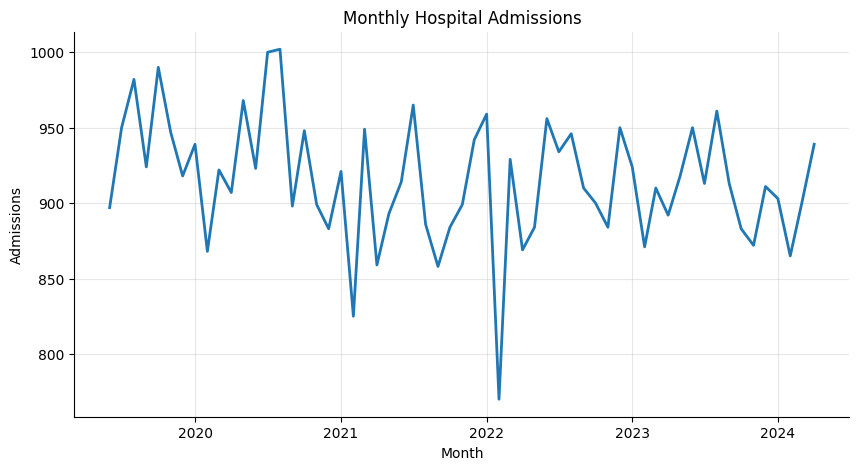

Average admissions per month: 915
Busiest month: Aug 2020 with 1002
Quietest month: Feb 2022 with 770


In [11]:
# Q1: What are the monthly trends in hospital admissions?
monthly_admissions = admissions_clean.groupby("Admission Month").size()
monthly_admissions = monthly_admissions.iloc[1:-1]   # first and last months are partial

plt.plot(monthly_admissions.index, monthly_admissions.values, color=main_color, linewidth=2)
plt.title("Monthly Hospital Admissions")
plt.xlabel("Month")
plt.ylabel("Admissions")
plt.grid(alpha=0.3)
plt.show()
print("Average admissions per month:", round(monthly_admissions.mean()))
print("Busiest month:", monthly_admissions.idxmax().strftime("%b %Y"), "with", monthly_admissions.max())
print("Quietest month:", monthly_admissions.idxmin().strftime("%b %Y"), "with", monthly_admissions.min())

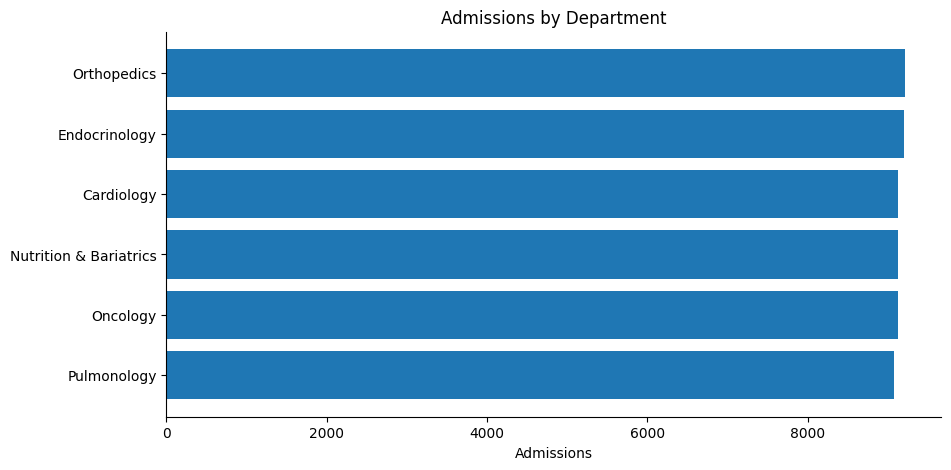

Department
Orthopedics               9207
Endocrinology             9197
Cardiology                9131
Nutrition & Bariatrics    9127
Oncology                  9121
Pulmonology               9077
Name: count, dtype: int64


In [12]:
# Q2: Which departments receive the highest number of patients?
department_patients = admissions_clean["Department"].value_counts()

plt.barh(department_patients.index[::-1], department_patients.values[::-1], color=main_color)
plt.title("Admissions by Department")
plt.xlabel("Admissions")
plt.show()
print(department_patients)

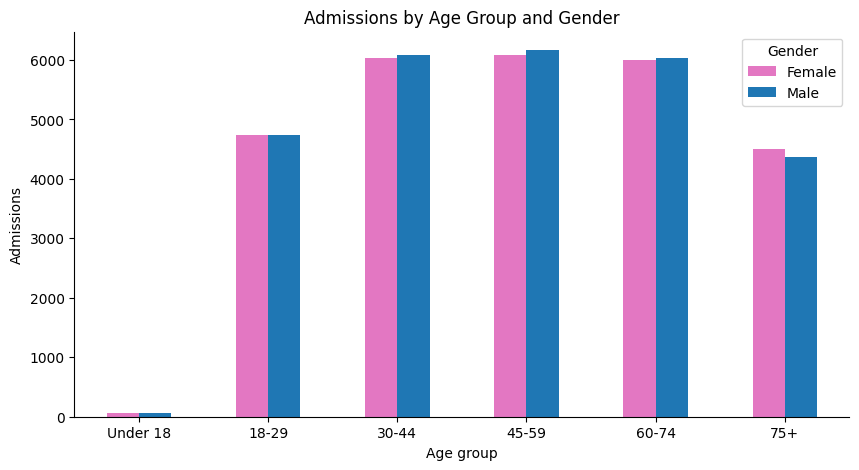

Gender     Female  Male
Age Group              
Under 18       55    61
18-29        4737  4736
30-44        6031  6075
45-59        6091  6166
60-74        5991  6036
75+          4506  4375

Share of admissions aged 45-74 (%): 44.3


In [13]:
# Q3: What patient demographics contribute the highest hospital utilization?
age_gender_counts = admissions_clean.groupby(["Age Group", "Gender"], observed=True).size().unstack()

age_gender_counts.plot(kind="bar", color=["#e377c2", main_color])
plt.title("Admissions by Age Group and Gender")
plt.xlabel("Age group")
plt.ylabel("Admissions")
plt.xticks(rotation=0)
plt.show()
print(age_gender_counts)
print()
print("Share of admissions aged 45-74 (%):", round(admissions_clean["Age Group"].isin(["45-59", "60-74"]).mean() * 100, 1))

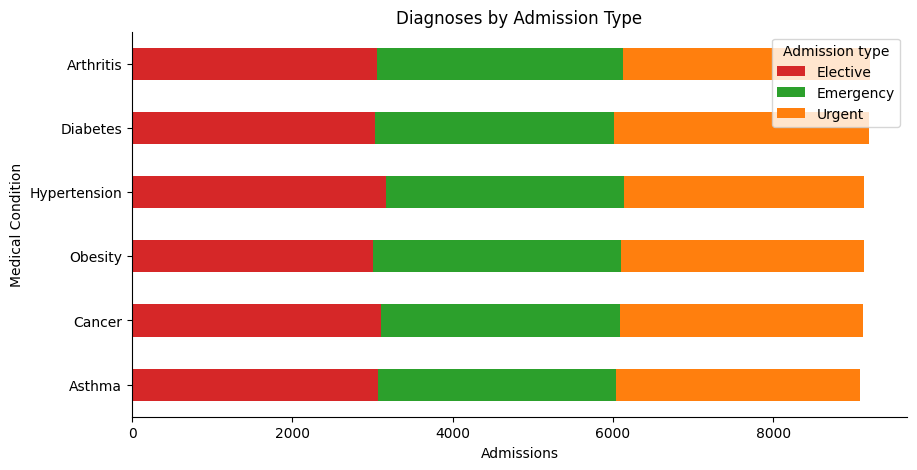

Admission Type     Elective  Emergency  Urgent
Medical Condition                             
Asthma                 3064       2973    3040
Cancer                 3108       2983    3030
Obesity                3009       3092    3026
Hypertension           3171       2970    2990
Diabetes               3027       2982    3188
Arthritis              3058       3070    3079


In [14]:
# Q4: What are the most common diagnoses and how do patients arrive (admission type)?
condition_by_type = admissions_clean.groupby(["Medical Condition", "Admission Type"]).size().unstack()
condition_by_type = condition_by_type.loc[condition_by_type.sum(axis=1).sort_values().index]

condition_by_type.plot(kind="barh", stacked=True, color=["#d62728", "#2ca02c", "#ff7f0e"])
plt.title("Diagnoses by Admission Type")
plt.xlabel("Admissions")
plt.legend(title="Admission type")
plt.show()
print(condition_by_type)

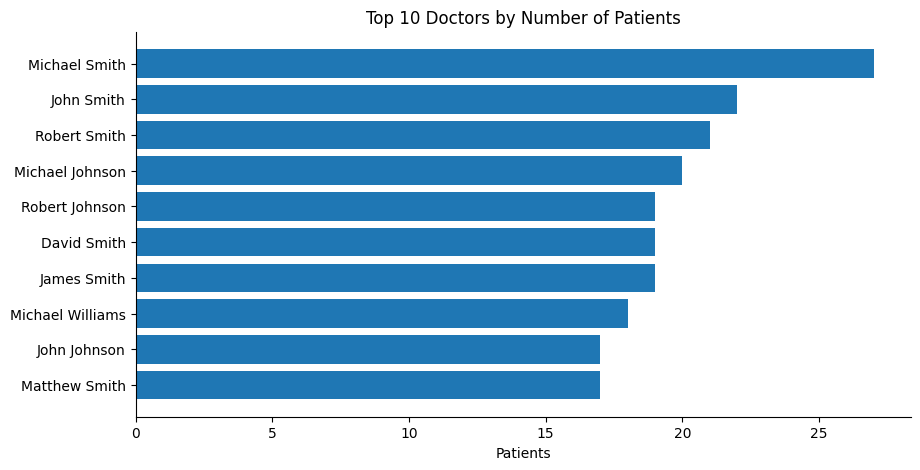

                  Patients    Revenue  Avg_Stay  Normal_Rate
Doctor                                                      
Michael Smith           27  784501.82     15.63         0.22
John Smith              22  610109.62     14.36         0.41
Robert Smith            21  609160.69     13.81         0.33
Michael Johnson         20  460819.02     18.70         0.65
Robert Johnson          19  524193.02     13.79         0.26
David Smith             19  473345.59     15.32         0.37
James Smith             19  461953.63     17.68         0.26
Michael Williams        18  309091.08     15.50         0.50
John Johnson            17  466769.96     18.06         0.35
Matthew Smith           17  421435.16     13.76         0.65

Total doctors: 40276
Doctors with only 1 patient: 30892
Average patients per doctor: 1.36


In [15]:
# Q5: Which doctors handle the highest number of patients?
doctor_summary = admissions_clean.groupby("Doctor").agg(
    Patients=("Admission ID", "count"),
    Revenue=("Billing Amount", "sum"),
    Avg_Stay=("Length of Stay", "mean"),
    Normal_Rate=("Good Outcome", "mean"),
).sort_values(["Patients", "Revenue"], ascending=False)

top_doctors = doctor_summary.head(10)
plt.barh(top_doctors.index[::-1], top_doctors["Patients"].values[::-1], color=main_color)
plt.title("Top 10 Doctors by Number of Patients")
plt.xlabel("Patients")
plt.show()
print(top_doctors.round(2))
print()
print("Total doctors:", len(doctor_summary))
print("Doctors with only 1 patient:", (doctor_summary["Patients"] == 1).sum())
print("Average patients per doctor:", round(doctor_summary["Patients"].mean(), 2))

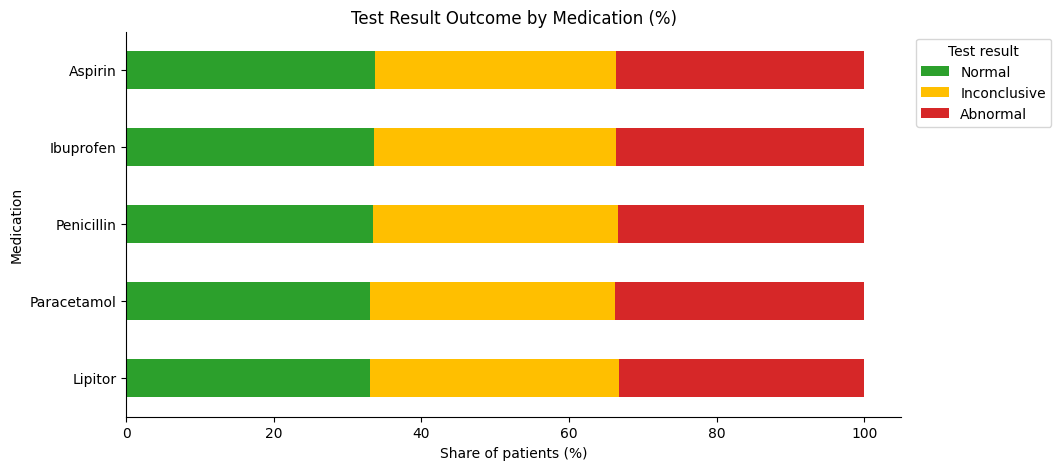

Test Results  Normal  Inconclusive  Abnormal
Medication                                  
Lipitor         33.1          33.7      33.2
Paracetamol     33.1          33.2      33.7
Penicillin      33.5          33.1      33.4
Ibuprofen       33.5          32.8      33.6
Aspirin         33.7          32.7      33.7


In [16]:
# Q6: Which treatments (medications) show the best patient outcomes?
medication_outcome = pd.crosstab(admissions_clean["Medication"], admissions_clean["Test Results"], normalize="index") * 100
medication_outcome = medication_outcome[["Normal", "Inconclusive", "Abnormal"]].sort_values("Normal")

medication_outcome.plot(kind="barh", stacked=True, color=["#2ca02c", "#ffbf00", "#d62728"])
plt.title("Test Result Outcome by Medication (%)")
plt.xlabel("Share of patients (%)")
plt.legend(title="Test result", bbox_to_anchor=(1.01, 1))
plt.show()
print(medication_outcome.round(1))

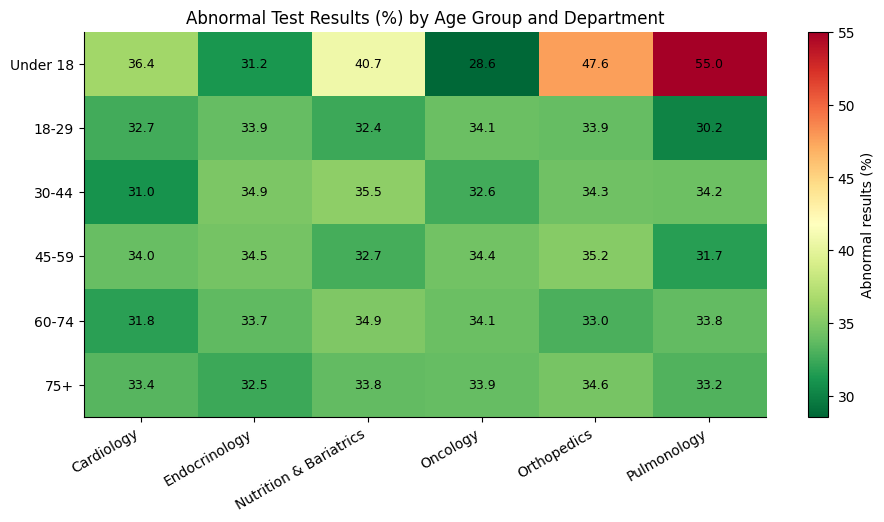

Lowest cell: 28.6 | Highest cell: 55.0
Overall abnormal rate (%): 33.5


In [17]:
# Q7: Are there relationships between demographics, diagnosis and outcomes?
# percentage of abnormal test results for each age group and department
abnormal_matrix = admissions_clean.pivot_table(index="Age Group", columns="Department", values="Abnormal Result", aggfunc="mean", observed=True) * 100

plt.figure(figsize=(11, 5))
plt.imshow(abnormal_matrix.values, cmap="RdYlGn_r", aspect="auto")
plt.xticks(range(len(abnormal_matrix.columns)), abnormal_matrix.columns, rotation=30, ha="right")
plt.yticks(range(len(abnormal_matrix.index)), abnormal_matrix.index)
for row in range(abnormal_matrix.shape[0]):
    for col in range(abnormal_matrix.shape[1]):
        plt.text(col, row, round(abnormal_matrix.values[row, col], 1), ha="center", va="center", fontsize=9)
plt.colorbar(label="Abnormal results (%)")
plt.title("Abnormal Test Results (%) by Age Group and Department")
plt.show()
print("Lowest cell:", round(abnormal_matrix.values.min(), 1), "| Highest cell:", round(abnormal_matrix.values.max(), 1))
print("Overall abnormal rate (%):", round(admissions_clean["Abnormal Result"].mean() * 100, 1))

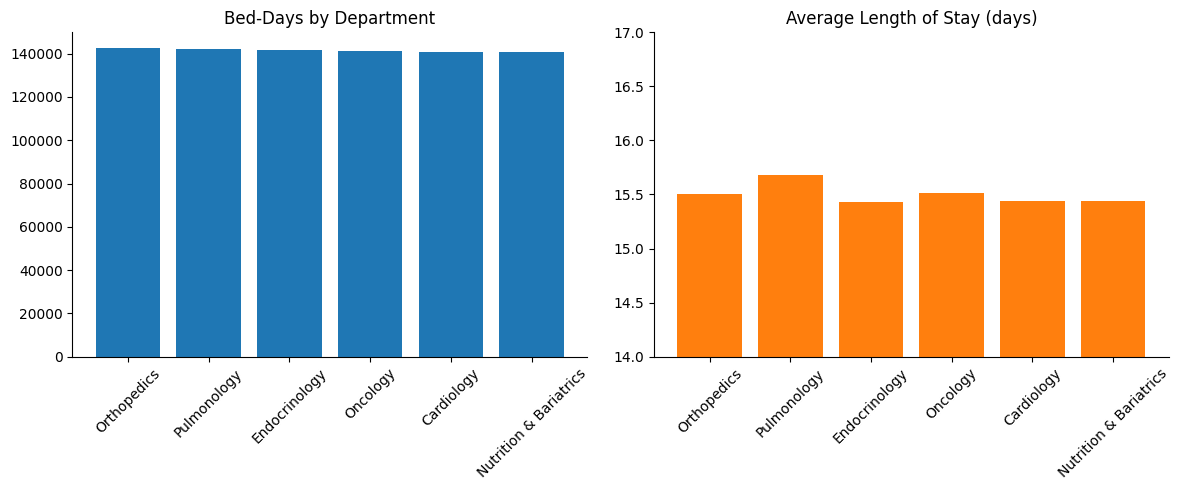

                        Admissions  Bed_Days  Avg_Stay
Department                                            
Orthopedics                   9207    142743     15.50
Pulmonology                   9077    142292     15.68
Endocrinology                 9197    141905     15.43
Oncology                      9121    141468     15.51
Cardiology                    9131    140941     15.44
Nutrition & Bariatrics        9127    140916     15.44


In [18]:
# Q8: Which departments carry the highest operational workload?
# workload is measured in bed-days (admissions x length of stay)
department_workload = admissions_clean.groupby("Department").agg(
    Admissions=("Admission ID", "count"),
    Bed_Days=("Length of Stay", "sum"),
    Avg_Stay=("Length of Stay", "mean"),
).sort_values("Bed_Days", ascending=False)

figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(department_workload.index, department_workload["Bed_Days"], color=main_color)
axes[0].set_title("Bed-Days by Department")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(department_workload.index, department_workload["Avg_Stay"], color="#ff7f0e")
axes[1].set_title("Average Length of Stay (days)")
axes[1].set_ylim(14, 17)
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
print(department_workload.round(2))

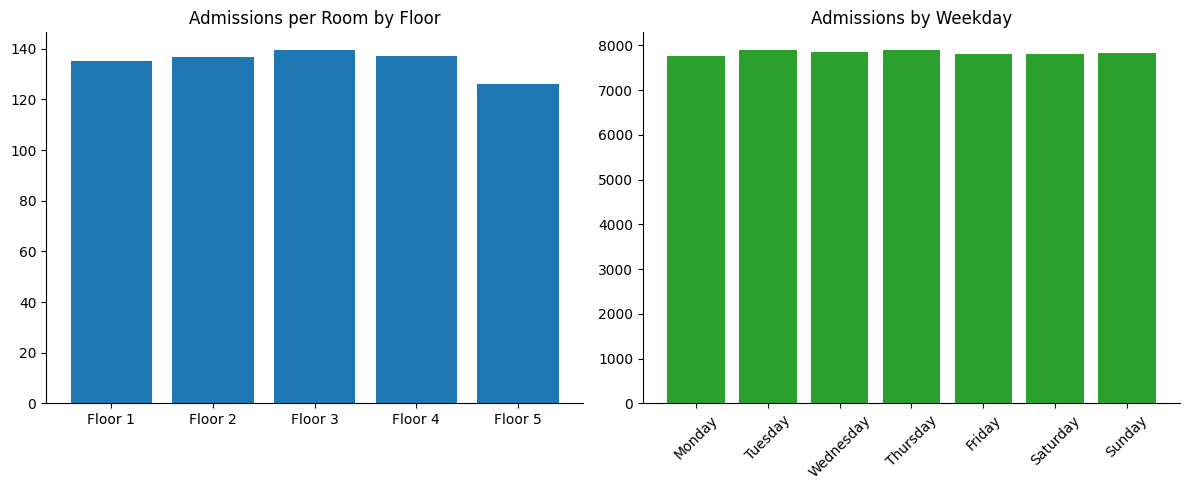

         Admissions  Bed_Days  Rooms  Admissions per Room
Floor                                                    
Floor 1       13385    209245     99                135.2
Floor 2       13684    210753    100                136.8
Floor 3       13948    216236    100                139.5
Floor 4       13717    212179    100                137.2
Floor 5         126      1852      1                126.0

Average length of stay by admission type:
Admission Type
Elective     15.51
Emergency    15.58
Urgent       15.41
Name: Length of Stay, dtype: float64


In [19]:
# Q9: How are hospital rooms and floors used?
floor_usage = admissions_clean.groupby("Floor").agg(
    Admissions=("Admission ID", "count"),
    Bed_Days=("Length of Stay", "sum"),
    Rooms=("Room Number", "nunique"),
)
floor_usage["Admissions per Room"] = floor_usage["Admissions"] / floor_usage["Rooms"]

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_admissions = admissions_clean["Admission Weekday"].value_counts().reindex(weekday_order)

figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(floor_usage.index, floor_usage["Admissions per Room"], color=main_color)
axes[0].set_title("Admissions per Room by Floor")
axes[1].bar(weekday_admissions.index, weekday_admissions.values, color="#2ca02c")
axes[1].set_title("Admissions by Weekday")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
print(floor_usage.round(1))
print()
print("Average length of stay by admission type:")
print(admissions_clean.groupby("Admission Type")["Length of Stay"].mean().round(2))

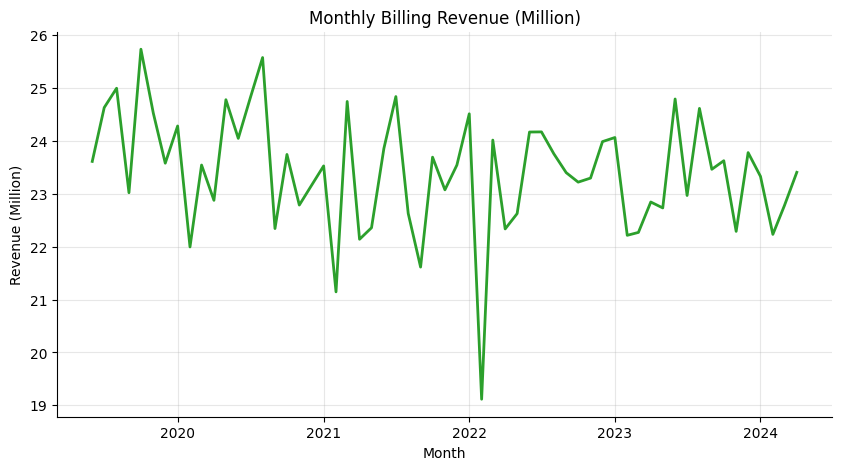

Admission Year
2019    187.5
2020    284.0
2021    277.2
2022    278.6
2023    279.7
2024     97.2
Name: Billing Amount, dtype: float64
Average monthly revenue (Million): 23.4


In [20]:
# Q10: What are the monthly billing and revenue trends?
monthly_revenue = admissions_clean.groupby("Admission Month")["Billing Amount"].sum() / 1000000
monthly_revenue = monthly_revenue.iloc[1:-1]

plt.plot(monthly_revenue.index, monthly_revenue.values, color="#2ca02c", linewidth=2)
plt.title("Monthly Billing Revenue (Million)")
plt.xlabel("Month")
plt.ylabel("Revenue (Million)")
plt.grid(alpha=0.3)
plt.show()

yearly_revenue = admissions_clean.groupby("Admission Year")["Billing Amount"].sum() / 1000000
print(yearly_revenue.round(1))
print("Average monthly revenue (Million):", round(monthly_revenue.mean(), 1))

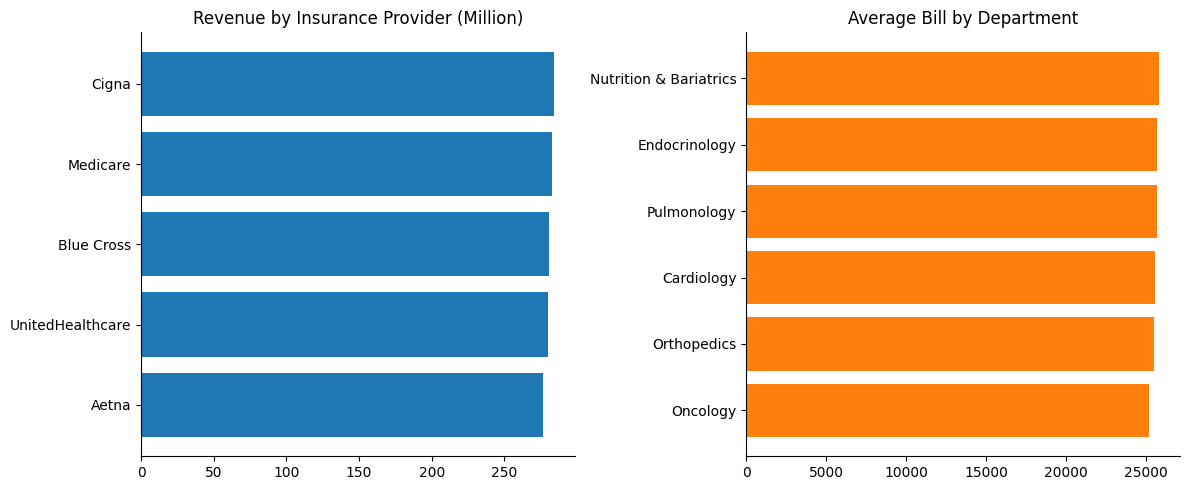

Insurance Provider
Aetna               276.5
UnitedHealthcare    279.9
Blue Cross          280.4
Medicare            282.9
Cigna               284.3
Name: Billing Amount, dtype: float64

Average bill by admission type:
Admission Type
Elective     25663.0
Emergency    25551.0
Urgent       25568.0
Name: Billing Amount, dtype: float64

Average bill by medication:
Medication
Aspirin        25647.0
Ibuprofen      25795.0
Lipitor        25385.0
Paracetamol    25605.0
Penicillin     25541.0
Name: Billing Amount, dtype: float64


In [21]:
# Q11: Which patient and treatment categories generate the highest healthcare costs?
insurance_revenue = admissions_clean.groupby("Insurance Provider")["Billing Amount"].sum().sort_values() / 1000000
department_average_bill = admissions_clean.groupby("Department")["Billing Amount"].mean().sort_values()

figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(insurance_revenue.index, insurance_revenue.values, color=main_color)
axes[0].set_title("Revenue by Insurance Provider (Million)")
axes[1].barh(department_average_bill.index, department_average_bill.values, color="#ff7f0e")
axes[1].set_title("Average Bill by Department")
plt.tight_layout()
plt.show()

print(insurance_revenue.round(1))
print()
print("Average bill by admission type:")
print(admissions_clean.groupby("Admission Type")["Billing Amount"].mean().round(0))
print()
print("Average bill by medication:")
print(admissions_clean.groupby("Medication")["Billing Amount"].mean().round(0))

In [22]:
# Q12: Does length of stay or age drive the cost?
print("Correlation between stay and bill:", round(admissions_clean["Length of Stay"].corr(admissions_clean["Billing Amount"]), 3))
print("Correlation between age and bill:", round(admissions_clean["Age"].corr(admissions_clean["Billing Amount"]), 3))
print()
print("Share of revenue from each billing band (%):")
print((admissions_clean.groupby("Billing Band", observed=True)["Billing Amount"].sum() / total_revenue * 100).round(1))

Correlation between stay and bill: -0.005
Correlation between age and bill: -0.003

Share of revenue from each billing band (%):
Billing Band
Under 10k     4.0
10k-20k      11.8
20k-30k      20.1
30k-40k      27.8
40k+         36.3
Name: Billing Amount, dtype: float64


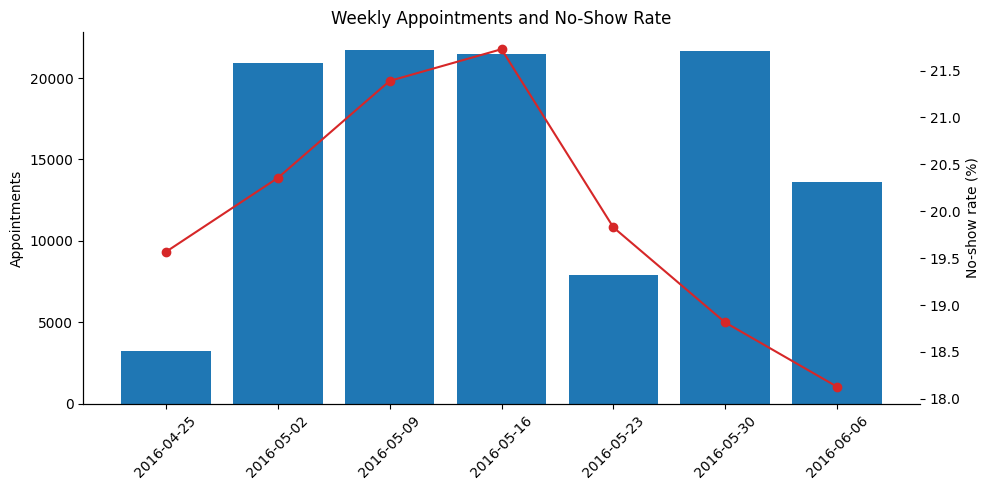

                  Appointments  No_Show_Rate
Appointment Week                            
2016-04-25                3235          19.6
2016-05-02               20948          20.4
2016-05-09               21721          21.4
2016-05-16               21452          21.7
2016-05-23                7918          19.8
2016-05-30               21654          18.8
2016-06-06               13586          18.1

Appointment dates range: 2016-04-29 to 2016-06-08


In [23]:
# Q13: What is the weekly appointment trend and how does the no-show rate move?
weekly_appointments = appointments_clean.groupby("Appointment Week").agg(
    Appointments=("Appointment ID", "count"),
    No_Show_Rate=("No Show Flag", "mean"),
)
weekly_appointments["No_Show_Rate"] = weekly_appointments["No_Show_Rate"] * 100

figure, axis_one = plt.subplots()
axis_one.bar(weekly_appointments.index.astype(str), weekly_appointments["Appointments"], color=main_color)
axis_one.set_ylabel("Appointments")
axis_one.tick_params(axis="x", rotation=45)
axis_two = axis_one.twinx()
axis_two.plot(weekly_appointments.index.astype(str), weekly_appointments["No_Show_Rate"], color="#d62728", marker="o")
axis_two.set_ylabel("No-show rate (%)")
plt.title("Weekly Appointments and No-Show Rate")
plt.tight_layout()
plt.show()
print(weekly_appointments.round(1))
print()
print("Appointment dates range:", appointments_clean["Appointment Day"].min().date(), "to", appointments_clean["Appointment Day"].max().date())

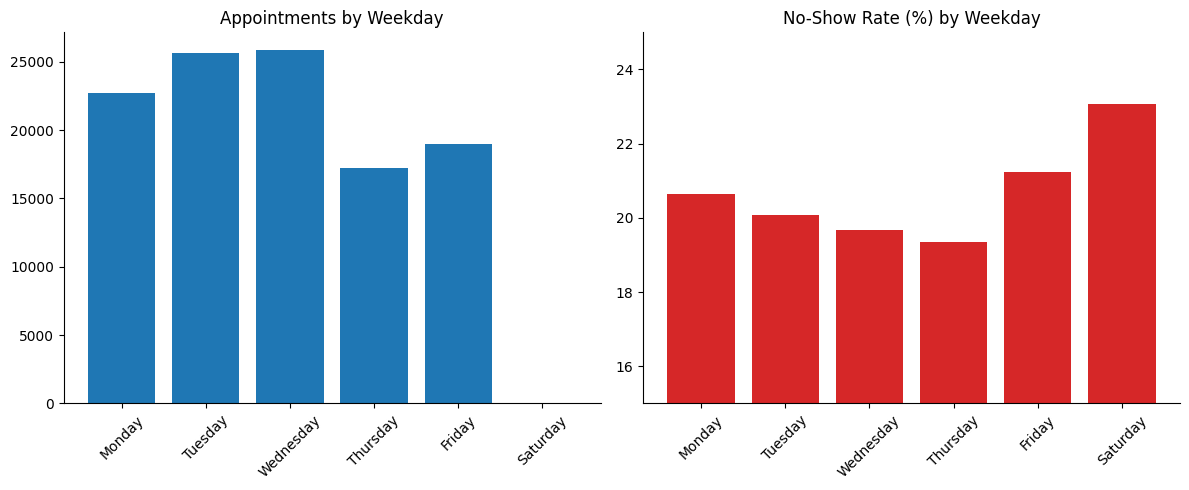

                     Appointments  No_Show_Rate
Appointment Weekday                            
Monday                    22711.0          20.6
Tuesday                   25637.0          20.1
Wednesday                 25866.0          19.7
Thursday                  17243.0          19.3
Friday                    19018.0          21.2
Saturday                     39.0          23.1


In [24]:
# Q14: Which day of the week has the most appointments and no-shows?
weekday_appointments = appointments_clean.groupby("Appointment Weekday").agg(
    Appointments=("Appointment ID", "count"),
    No_Show_Rate=("No Show Flag", "mean"),
).reindex(weekday_order).dropna()
weekday_appointments["No_Show_Rate"] = weekday_appointments["No_Show_Rate"] * 100

figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(weekday_appointments.index, weekday_appointments["Appointments"], color=main_color)
axes[0].set_title("Appointments by Weekday")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(weekday_appointments.index, weekday_appointments["No_Show_Rate"], color="#d62728")
axes[1].set_title("No-Show Rate (%) by Weekday")
axes[1].set_ylim(15, 25)
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
print(weekday_appointments.round(1))

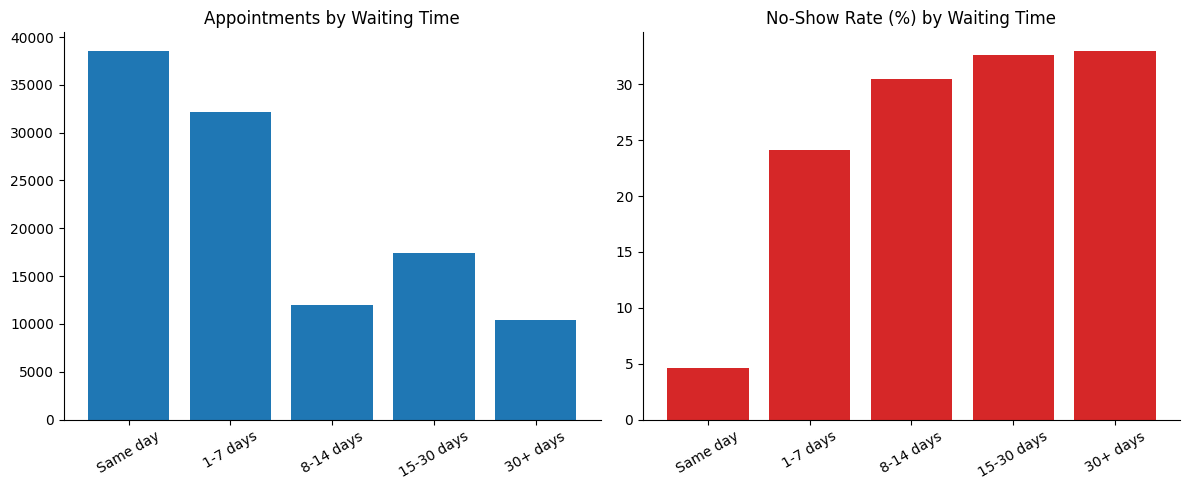

            Appointments  No_Show_Rate
Wait Band                             
Same day           38560           4.6
1-7 days           32182          24.1
8-14 days          12025          30.5
15-30 days         17370          32.6
30+ days           10377          33.0

Average wait (days): 10.2 | Median: 4.0
Same day appointments (%): 34.9


In [25]:
# Q15: What is the average waiting time and how does it affect no-shows?
wait_summary = appointments_clean.groupby("Wait Band", observed=True).agg(
    Appointments=("Appointment ID", "count"),
    No_Show_Rate=("No Show Flag", "mean"),
)
wait_summary["No_Show_Rate"] = wait_summary["No_Show_Rate"] * 100

figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(wait_summary.index, wait_summary["Appointments"], color=main_color)
axes[0].set_title("Appointments by Waiting Time")
axes[0].tick_params(axis="x", rotation=30)
axes[1].bar(wait_summary.index, wait_summary["No_Show_Rate"], color="#d62728")
axes[1].set_title("No-Show Rate (%) by Waiting Time")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print(wait_summary.round(1))
print()
print("Average wait (days):", round(appointments_clean["Wait Days"].mean(), 1), "| Median:", appointments_clean["Wait Days"].median())
print("Same day appointments (%):", round((appointments_clean["Wait Days"] == 0).mean() * 100, 1))

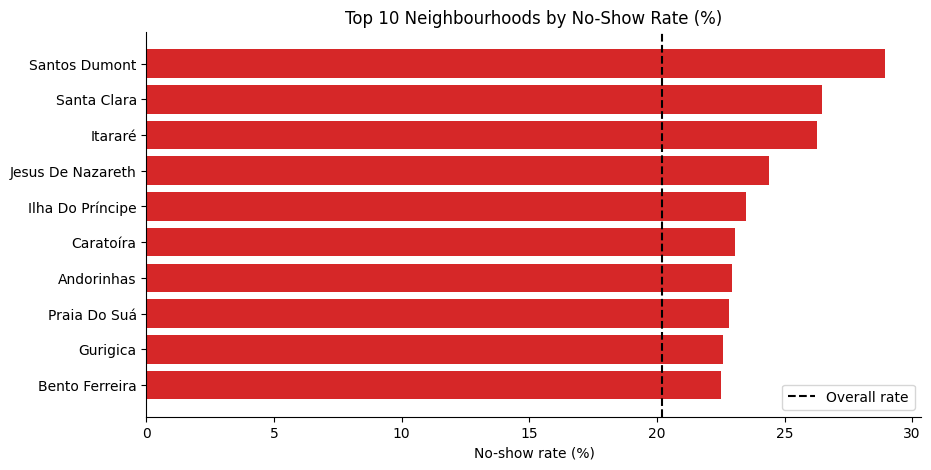

                   Appointments  No_Show_Rate
Neighbourhood                                
Santos Dumont              1276          28.9
Santa Clara                 506          26.5
Itararé                    3514          26.3
Jesus De Nazareth          2853          24.4
Ilha Do Príncipe           2266          23.5
Caratoíra                  2565          23.0
Andorinhas                 2258          22.9
Praia Do Suá               1288          22.8
Gurigica                   2018          22.6
Bento Ferreira              858          22.5

Lowest no-show neighbourhoods:
                 Appointments  No_Show_Rate
Neighbourhood                              
Do Cabral                 560          15.7
Santa Martha             3131          15.8
Jardim Da Penha          3877          16.3


In [26]:
# Q16: Which neighbourhoods (clinic locations) have the highest no-show rates?
neighbourhood_summary = appointments_clean.groupby("Neighbourhood").agg(
    Appointments=("Appointment ID", "count"),
    No_Show_Rate=("No Show Flag", "mean"),
)
neighbourhood_summary["No_Show_Rate"] = neighbourhood_summary["No_Show_Rate"] * 100
# only neighbourhoods with enough appointments, so small groups do not distort the rates
neighbourhood_summary = neighbourhood_summary[neighbourhood_summary["Appointments"] >= 500]
worst_neighbourhoods = neighbourhood_summary.sort_values("No_Show_Rate", ascending=False).head(10)

plt.barh(worst_neighbourhoods.index[::-1], worst_neighbourhoods["No_Show_Rate"].values[::-1], color="#d62728")
plt.axvline(no_show_rate, color="black", linestyle="--", label="Overall rate")
plt.title("Top 10 Neighbourhoods by No-Show Rate (%)")
plt.xlabel("No-show rate (%)")
plt.legend()
plt.show()
print(worst_neighbourhoods.round(1))
print()
print("Lowest no-show neighbourhoods:")
print(neighbourhood_summary.sort_values("No_Show_Rate").head(3).round(1))

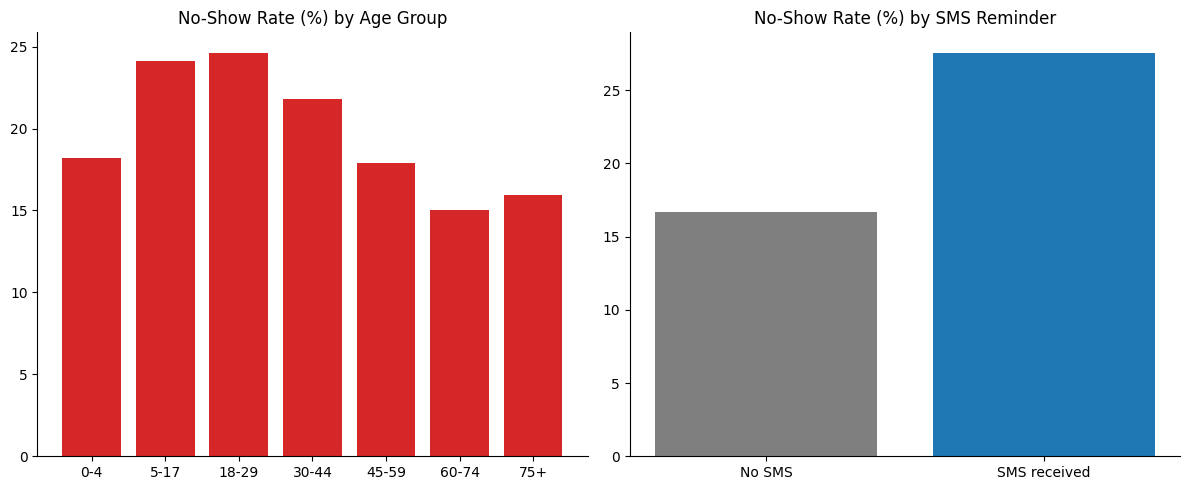

Age Group
0-4      18.2
5-17     24.1
18-29    24.6
30-44    21.8
45-59    17.9
60-74    15.0
75+      16.0
Name: No Show Flag, dtype: float64

SMS Received
0    16.7
1    27.6
Name: No Show Flag, dtype: float64

Welfare scholarship (0 = no, 1 = yes):
Scholarship
0    19.8
1    23.7
Name: No Show Flag, dtype: float64

By gender:
Gender
Female    20.3
Male      20.0
Name: No Show Flag, dtype: float64

By number of chronic conditions:
Chronic Conditions
0    20.9
1    17.9
2    17.9
3    15.4
4    30.8
Name: No Show Flag, dtype: float64


In [27]:
# Q17: Which patient groups miss appointments the most, and do SMS reminders help?
age_group_no_show = appointments_clean.groupby("Age Group", observed=True)["No Show Flag"].mean() * 100
sms_no_show = appointments_clean.groupby("SMS Received")["No Show Flag"].mean() * 100
scholarship_no_show = appointments_clean.groupby("Scholarship")["No Show Flag"].mean() * 100

figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(age_group_no_show.index, age_group_no_show.values, color="#d62728")
axes[0].set_title("No-Show Rate (%) by Age Group")
axes[1].bar(["No SMS", "SMS received"], sms_no_show.values, color=["#7f7f7f", main_color])
axes[1].set_title("No-Show Rate (%) by SMS Reminder")
plt.tight_layout()
plt.show()

print(age_group_no_show.round(1))
print()
print(sms_no_show.round(1))
print()
print("Welfare scholarship (0 = no, 1 = yes):")
print(scholarship_no_show.round(1))
print()
print("By gender:")
print((appointments_clean.groupby("Gender")["No Show Flag"].mean() * 100).round(1))
print()
print("By number of chronic conditions:")
print((appointments_clean.groupby("Chronic Conditions")["No Show Flag"].mean() * 100).round(1))

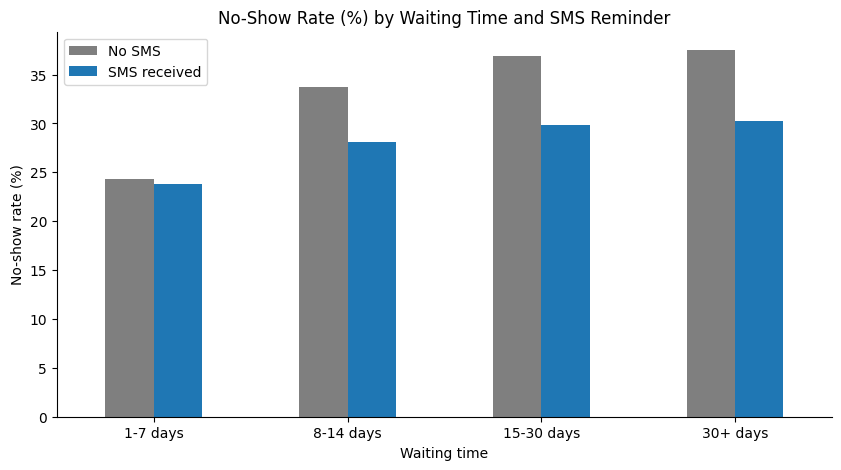

            No SMS  SMS received
Wait Band                       
1-7 days      24.4          23.8
8-14 days     33.8          28.1
15-30 days    36.9          29.8
30+ days      37.5          30.2

Same day appointments that received an SMS: 0


In [28]:
# Q18: SMS patients miss MORE appointments overall - is that real?
# SMS reminders are only sent for appointments booked days ahead, and those already have a high no-show rate.
# So we compare SMS and no SMS inside each waiting-time band.
sms_by_wait = appointments_clean.pivot_table(index="Wait Band", columns="SMS Received", values="No Show Flag", aggfunc="mean", observed=True) * 100
sms_by_wait.columns = ["No SMS", "SMS received"]
sms_by_wait = sms_by_wait.drop("Same day")   # no SMS were sent for same day bookings

sms_by_wait.plot(kind="bar", color=["#7f7f7f", main_color])
plt.title("No-Show Rate (%) by Waiting Time and SMS Reminder")
plt.xlabel("Waiting time")
plt.ylabel("No-show rate (%)")
plt.xticks(rotation=0)
plt.show()
print(sms_by_wait.round(1))
print()
print("Same day appointments that received an SMS:", appointments_clean[(appointments_clean["Wait Days"] == 0) & (appointments_clean["SMS Received"] == 1)].shape[0])

In [29]:
# Step 11: build the date tables and the department table for Power BI
admission_dates = pd.date_range(admissions_clean["Date of Admission"].min().replace(day=1), admissions_clean["Discharge Date"].max(), freq="D")
date_table = pd.DataFrame({"Date": admission_dates})
date_table["Year"] = date_table["Date"].dt.year
date_table["Quarter"] = "Q" + date_table["Date"].dt.quarter.astype(str)
date_table["Month Number"] = date_table["Date"].dt.month
date_table["Month"] = date_table["Date"].dt.strftime("%b")
date_table["Year Month"] = date_table["Date"].dt.strftime("%Y-%m")
date_table["Weekday"] = date_table["Date"].dt.day_name()
date_table["Weekday Number"] = date_table["Date"].dt.dayofweek + 1

appointment_dates = pd.date_range(appointments_clean["Scheduled Day"].min(), appointments_clean["Appointment Day"].max(), freq="D")
appointment_date_table = pd.DataFrame({"Date": appointment_dates})
appointment_date_table["Year"] = appointment_date_table["Date"].dt.year
appointment_date_table["Month Number"] = appointment_date_table["Date"].dt.month
appointment_date_table["Month"] = appointment_date_table["Date"].dt.strftime("%b")
appointment_date_table["Week Start"] = appointment_date_table["Date"].dt.to_period("W").dt.start_time
appointment_date_table["Weekday"] = appointment_date_table["Date"].dt.day_name()
appointment_date_table["Weekday Number"] = appointment_date_table["Date"].dt.dayofweek + 1

department_table = pd.DataFrame({
    "Department": list(department_map.values()),
    "Medical Condition": list(department_map.keys()),
})
print(len(date_table), len(appointment_date_table), len(department_table))

1864 212 6


In [30]:
# Step 12: table of the cleaning steps
cleaning_summary = pd.DataFrame({
    "Dataset": ["Admissions"] * 5 + ["Appointments"] * 5,
    "Step": [
        "Removed exact duplicate rows",
        "Fixed random upper/lower case in patient and doctor names",
        "Removed rows with negative billing amounts",
        "Converted admission and discharge dates to date type",
        "Created length of stay, age group, department, floor, billing band, outcome flags",
        "Renamed misspelled columns (Hipertension, Handcap, No-show)",
        "Removed rows with impossible ages (negative or above 100)",
        "Converted scheduled and appointment timestamps to dates",
        "Removed rows booked after the appointment date (negative wait)",
        "Created wait days, wait band, age group, no-show flag, chronic condition count",
    ],
    "Rows Affected": [
        duplicates_removed, len(admissions_clean), negative_billing_removed, len(admissions_clean), len(admissions_clean),
        len(appointments_clean), invalid_age_removed, len(appointments_clean), negative_wait_rows, len(appointments_clean),
    ],
})
print(cleaning_summary)

        Dataset                                               Step  \
0    Admissions                       Removed exact duplicate rows   
1    Admissions  Fixed random upper/lower case in patient and d...   
2    Admissions         Removed rows with negative billing amounts   
3    Admissions  Converted admission and discharge dates to dat...   
4    Admissions  Created length of stay, age group, department,...   
5  Appointments  Renamed misspelled columns (Hipertension, Hand...   
6  Appointments  Removed rows with impossible ages (negative or...   
7  Appointments  Converted scheduled and appointment timestamps...   
8  Appointments  Removed rows booked after the appointment date...   
9  Appointments  Created wait days, wait band, age group, no-sh...   

   Rows Affected  
0            534  
1          54860  
2            106  
3          54860  
4          54860  
5         110514  
6              8  
7         110514  
8              5  
9         110514  


In [31]:
# Step 13: DAX measures and data dictionary sheets
dax_measures = pd.DataFrame({
    "Table": ["Admissions"] * 9 + ["Appointments"] * 9,
    "Measure": [
        "Total Admissions", "Total Revenue", "Average Bill", "Average Length of Stay", "Bed Days",
        "Normal Result Rate", "Abnormal Result Rate", "Revenue per Bed Day", "Revenue MoM %",
        "Total Appointments", "Unique Patients", "No-Show Count", "No-Show Rate", "Attendance Rate",
        "Average Wait Days", "Same Day Rate", "SMS No-Show Rate", "No SMS No-Show Rate",
    ],
    "DAX": [
        "Total Admissions = COUNTROWS(Admissions)",
        "Total Revenue = SUM(Admissions[Billing Amount])",
        "Average Bill = DIVIDE([Total Revenue], [Total Admissions])",
        "Average Length of Stay = AVERAGE(Admissions[Length of Stay])",
        "Bed Days = SUM(Admissions[Length of Stay])",
        "Normal Result Rate = DIVIDE(SUM(Admissions[Good Outcome]), [Total Admissions])",
        "Abnormal Result Rate = DIVIDE(SUM(Admissions[Abnormal Result]), [Total Admissions])",
        "Revenue per Bed Day = DIVIDE([Total Revenue], [Bed Days])",
        "Revenue MoM % = VAR PrevRevenue = CALCULATE([Total Revenue], DATEADD(Dim_Date[Date], -1, MONTH)) RETURN DIVIDE([Total Revenue] - PrevRevenue, PrevRevenue)",
        "Total Appointments = COUNTROWS(Appointments)",
        "Unique Patients = DISTINCTCOUNT(Appointments[Patient ID])",
        "No-Show Count = SUM(Appointments[No Show Flag])",
        "No-Show Rate = DIVIDE([No-Show Count], [Total Appointments])",
        "Attendance Rate = 1 - [No-Show Rate]",
        "Average Wait Days = AVERAGE(Appointments[Wait Days])",
        "Same Day Rate = DIVIDE(CALCULATE([Total Appointments], Appointments[Wait Days] = 0), [Total Appointments])",
        "SMS No-Show Rate = CALCULATE([No-Show Rate], Appointments[SMS Received] = 1)",
        "No SMS No-Show Rate = CALCULATE([No-Show Rate], Appointments[SMS Received] = 0)",
    ],
})

data_dictionary = pd.DataFrame({
    "Table": ["Admissions"] * 6 + ["Appointments"] * 6,
    "Column": ["Department", "Floor", "Length of Stay", "Good Outcome", "Abnormal Result", "Age Group",
               "No Show Flag", "Wait Days", "Wait Band", "Chronic Conditions", "Status", "Age Group"],
    "Meaning": [
        "Derived from Medical Condition (the source has no department column)",
        "First digit of the room number",
        "Discharge date minus admission date, in days",
        "1 if test result is Normal",
        "1 if test result is Abnormal",
        "Age bucket",
        "1 if the patient did not attend",
        "Appointment date minus booking date, in days",
        "Waiting time bucket",
        "Count of hypertension, diabetes, alcoholism and handicap flags",
        "Attended or No-Show",
        "Age bucket",
    ],
})
print(dax_measures[["Table", "Measure"]])

           Table                 Measure
0     Admissions        Total Admissions
1     Admissions           Total Revenue
2     Admissions            Average Bill
3     Admissions  Average Length of Stay
4     Admissions                Bed Days
5     Admissions      Normal Result Rate
6     Admissions    Abnormal Result Rate
7     Admissions     Revenue per Bed Day
8     Admissions           Revenue MoM %
9   Appointments      Total Appointments
10  Appointments         Unique Patients
11  Appointments           No-Show Count
12  Appointments            No-Show Rate
13  Appointments         Attendance Rate
14  Appointments       Average Wait Days
15  Appointments           Same Day Rate
16  Appointments        SMS No-Show Rate
17  Appointments     No SMS No-Show Rate


In [32]:
# Step 14: save everything into one Excel file for Power BI
output_file = "Healthcare_Clean_Data.xlsx"
with pd.ExcelWriter(output_file, engine="xlsxwriter", datetime_format="yyyy-mm-dd") as excel_writer:
    admissions_clean.to_excel(excel_writer, sheet_name="Admissions", index=False)
    appointments_clean.to_excel(excel_writer, sheet_name="Appointments", index=False)
    date_table.to_excel(excel_writer, sheet_name="Dim_Date", index=False)
    appointment_date_table.to_excel(excel_writer, sheet_name="Dim_Appointment_Date", index=False)
    department_table.to_excel(excel_writer, sheet_name="Dim_Department", index=False)
    cleaning_summary.to_excel(excel_writer, sheet_name="Cleaning_Summary", index=False)
    dax_measures.to_excel(excel_writer, sheet_name="DAX_Measures", index=False)
    data_dictionary.to_excel(excel_writer, sheet_name="Data_Dictionary", index=False)
print("Saved", output_file)

Saved Healthcare_Clean_Data.xlsx
